# Análise exploratória das avaliações da Olist

Nesta análise eu olho os comentários das avaliações para definir quais entram na
base de conhecimento do RAG e como o texto vai ser tratado.

Os cálculos estão em `src/preparacao/exploracao.py`. O resumo com os números fica
gravado em `reports/analise_exploratoria.json`.

In [1]:
import os, sys, re
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from IPython.display import Image, display

from src.preparacao.carga import carregar_avaliacoes
from src.preparacao import exploracao as ex

bruto = carregar_avaliacoes()
resumo = ex.executar()
df = bruto.drop_duplicates("review_id")
print(f"{len(bruto):,} linhas no arquivo, {bruto.shape[1]} colunas".replace(",", "."))
bruto.head(3)

99.224 linhas no arquivo. 7 colunas


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


## 1. Avaliações repetidas

O arquivo tem 99.224 linhas e 98.410 `review_id` diferentes. Alguns `review_id`
aparecem em mais de um pedido.

In [2]:
pd.Series(resumo["volume"]).to_frame("valor")

,valor
linhas_no_arquivo,99224
review_id_unicos,98410
review_id_repetidos,789
linhas_removidas_na_deduplicacao,814
repetidos_com_nota_ou_texto_diferente,0
pedidos_com_mais_de_uma_avaliacao,547
periodo,"[2016-10-02, 2018-08-31]"


São 789 `review_id` repetidos. Em todos a nota e o texto são iguais nas duas
linhas, então é a mesma avaliação registrada em dois pedidos.

**Decisão:** manter uma avaliação por `review_id`.

## 2. Comentários por nota

41,3% das avaliações têm comentário. Esse percentual muda bastante de acordo com a
nota.

In [3]:
v = resumo["vies_de_selecao"]
pd.DataFrame({
    "com comentário (%)": v["pct_com_comentario_por_nota"],
    "% entre todas as avaliações": v["distribuicao_notas_todas"],
    "% entre as com comentário": v["distribuicao_notas_com_comentario"],
}).rename_axis("nota")

,com comentário (%),% entre todas as avaliações,% entre as com comentário
nota,,,
1,76.6,11.5,21.2
2,68.0,3.2,5.2
3,43.6,8.2,8.7
4,31.3,19.3,14.6
5,35.9,57.8,50.3


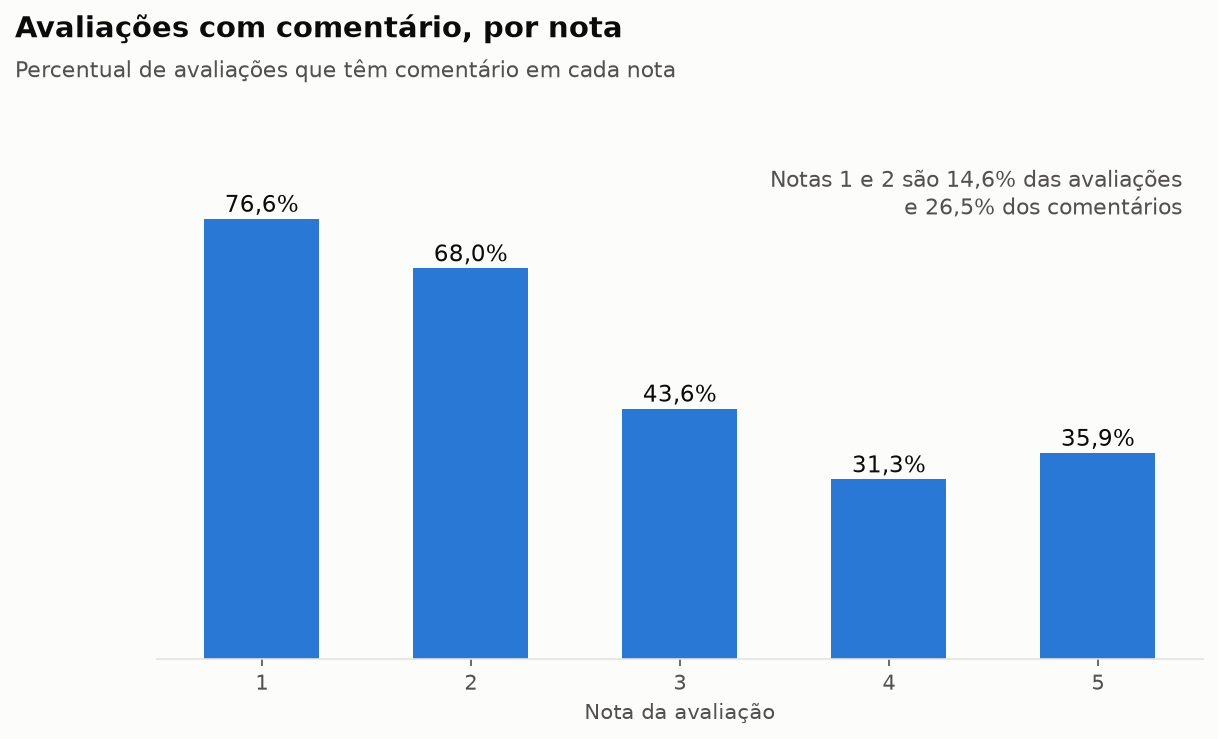

In [4]:
display(Image("../images/01_comentario_por_nota.png"))

Clientes que dão nota baixa comentam mais: 76,6% das avaliações com nota 1 têm
comentário, e 31,3% das avaliações com nota 4.

Com isso, as notas 1 e 2 somam 14,6% das avaliações e 26,5% dos comentários. A base
de conhecimento é formada pelos comentários, então ela tem proporcionalmente mais
reclamações que o total de avaliações.

**Decisão:** quando a resposta do sistema falar de frequência, ela vai se referir
aos comentários e não ao total de clientes.

## 3. Tamanho dos comentários

In [5]:
pd.Series(resumo["tamanho"]).to_frame("valor")

,valor
caracteres_mediana,53.0
caracteres_p90,161.0
caracteres_max,208.0
palavras_mediana,9.0
palavras_p90,28.0
exatamente_no_limite,654.0
a_ate_5_do_limite,1719.0
pct_a_ate_5_do_limite,4.2


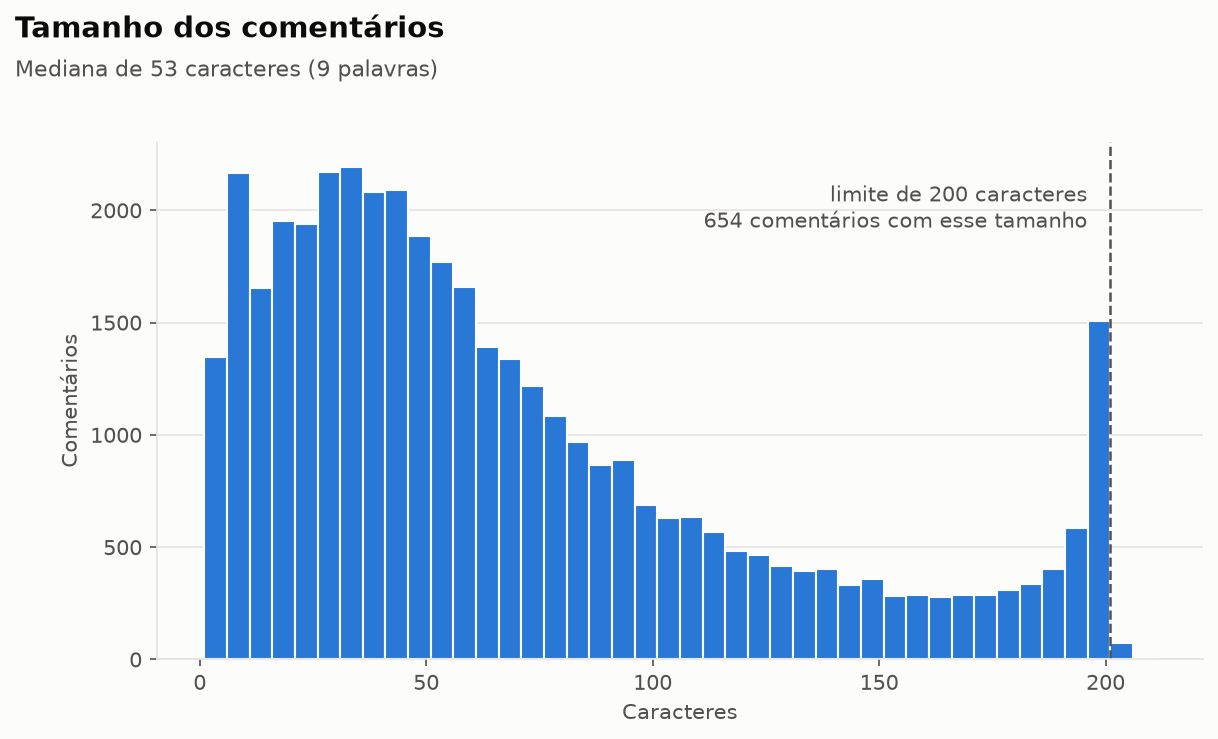

In [6]:
display(Image("../images/02_tamanho_comentarios.png"))

Os comentários são curtos, com mediana de 53 caracteres. A plataforma limita o
texto a 200 caracteres, e alguns comentários foram cortados no meio de uma palavra:

In [7]:
coment = df["review_comment_message"].dropna()
for t in coment[coment.str.len() >= 199].head(5):
    print("...", t[-70:])

... te de Eva Nº Letras 36 Peças Crianças 1 un - R$ 35,90 (ESTE FOI ENTREG
... to via e-mail qto por telef.O suspense terminou mas lá não compro mais
...  No site das lannister costumam chegar antes do prazo. Estranhei muito
... de 50,00 reais ... um produto com defeito e até agora não me deu retor
... sa saio correndo. Um absurdo. Quase um mês para entregar. Extra.com ok


**Decisão:** cada avaliação vai ser um documento da base, sem dividir o texto em
partes. Os textos cortados no limite são mantidos como estão.

## 4. Comentários genéricos

Muitos comentários são apenas um elogio curto, sem dizer qual parte da compra o
cliente avaliou.

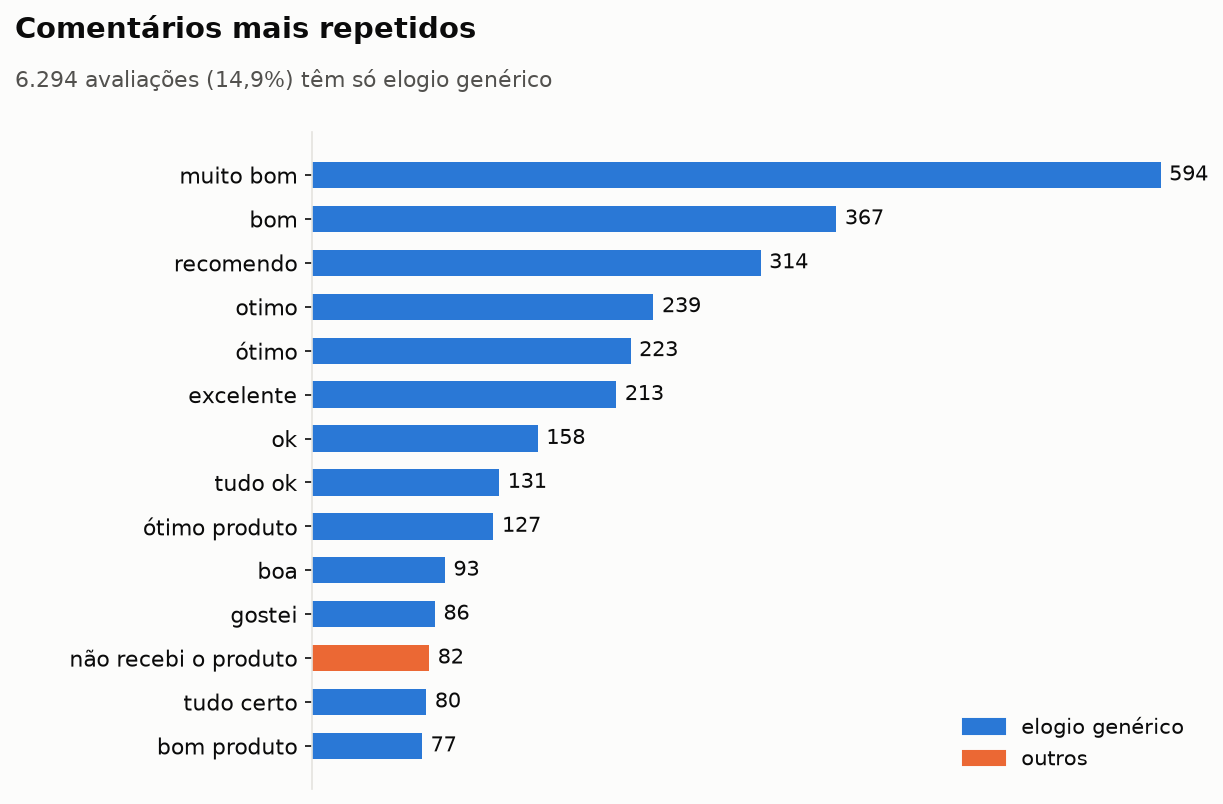

In [8]:
display(Image("../images/03_comentarios_mais_repetidos.png"))

In [9]:
pd.Series(resumo["informatividade"]).to_frame("valor")

,valor
avaliacoes_com_algum_texto,42293.00
so_elogio_generico,6294.00
pct_so_elogio_generico,14.90
nota_media_genericos,4.66
nota_media_demais,3.54
sem_nenhuma_palavra,42.00
previsao_base_de_conhecimento,35957.00


6.294 avaliações com texto (14,9%) têm apenas elogio genérico. A nota média
delas é 4,66, e a das demais é 3,54.

Para identificar esses casos usei uma lista de palavras genéricas (`VOCAB_GENERICO`).
Um comentário só é considerado genérico quando todas as suas palavras estão na
lista. Não usei o tamanho do texto como critério porque isso também tiraria
comentários curtos e úteis. A tabela abaixo mostra exemplos de comentários de uma
ou duas palavras que ficam e que saem.

In [10]:
texto = ex.texto_completo(df)
curtos = texto[texto.map(lambda t: 0 < len(ex.tokens(t)) <= 2)]
mantidos = curtos[~curtos.map(ex.eh_generico)].str.lower().value_counts().head(12)
excluidos = curtos[curtos.map(ex.eh_generico)].str.lower().value_counts().head(12)
pd.DataFrame({"mantido": mantidos.index, "excluído": excluidos.index})

,mantido,excluído
0,entrega rápida,muito bom
1,não recebi,bom
2,bom atendimento,recomendo
3,entrega rapida,ótimo
4,ótimo atendimento,otimo
5,ótimo vendedor,excelente
6,regular,super recomendo
7,excelente atendimento,ok
8,exelente,boa
9,otimo vendedor,tudo ok


**Decisão:** as avaliações só com elogio genérico e as que não têm nenhuma palavra
não entram na base. A previsão é de 35.957 documentos.

Como esses elogios vêm quase todos de clientes satisfeitos, a base fica com uma
parcela um pouco menor de comentários positivos. Os elogios que citam algum aspecto
da compra, como "chegou antes do prazo", continuam na base.

## 5. Ruído e dados pessoais

In [11]:
pd.DataFrame({
    "ocorrências": {**resumo["ruido"], **resumo["dados_pessoais"],
                    "termos de instrução": resumo["termos_de_instrucao"],
                    "lojas anonimizadas": resumo["lojas_anonimizadas"]}
})

,ocorrências
quebra_de_linha,3806
tudo_maiusculo,1096
letra_repetida_3x,256
emoji,288
e-mail,0
celular,2
link,2
CPF,0
termos de instrução,82
lojas anonimizadas,1951


**Quebra de linha:** 3.806 comentários têm quebra de linha, que vai ser trocada por
espaço. Maiúsculas, letras repetidas e emojis ficam como estão, para que a
avaliação apareça na resposta como o cliente escreveu.

**Dados pessoais:** encontrei 2 avaliações com celular e 2 com link, e nenhuma com
e-mail ou CPF. O detector de celular exige DDD seguido de 9 e o de CPF valida o
dígito verificador, para não confundir com número de pedido ou data. Os números não
são exibidos aqui.

**Termos de instrução:** 82 avaliações têm termos como "ignorar", "instruções" ou
"desconsiderar". Li todas. São clientes pedindo manual de instruções, dizendo que
foram ignorados pelo vendedor, e um caso pedindo para "desconsiderar a primeira
avaliação". Nenhuma é uma tentativa de manipular um modelo de linguagem.

In [12]:
inst = texto[texto.map(lambda t: bool(re.search(ex.TERMOS_INSTRUCAO, t, flags=re.I)))]
for t in inst.head(6):
    print("-", t[:120])

- Lindo... Só faltou instruções da troca de pulseiras
- Não realiza o que promete, depois de instalado fica vazando pelo cartucho, mesmo seguindo as instruções, não vale a pena
- Cartucho HP 60 colorido não funciona, impressora não reconhece como HP. Solicito instruções para devolução do produto e 
- Produto péssimo. Com emblema de ponta-cabeça (invertido) e contém avaria. Já fiz contato com a loja através do e-mail e 
- Transcorreu tudo bem. O vendedor não mandou instruções de cura
- O produto esquenta bastante, instruções para instalação em inglês, tive dificuldades na instalação


**Nomes de lojas:** 1.951 comentários citam nomes como "lannister", "stark" e
"targaryen". Na anonimização da base, os nomes das lojas foram trocados por esses
nomes. Por isso não é possível responder perguntas sobre uma loja pelo nome real.

**Decisão:** trocar quebra de linha por espaço e mascarar celular e link como
`[CELULAR]` e `[LINK]`. No prompt, as avaliações vão ficar separadas das instruções
do modelo e identificadas como dados.

## 6. Temas dos comentários

Para ter uma ideia dos assuntos mais citados, contei os comentários que têm
palavras-chave de cada tema. É uma estimativa simples, e um comentário pode citar
mais de um tema. Esses números vão ser usados na etapa de avaliação para comparar
com as respostas do sistema.

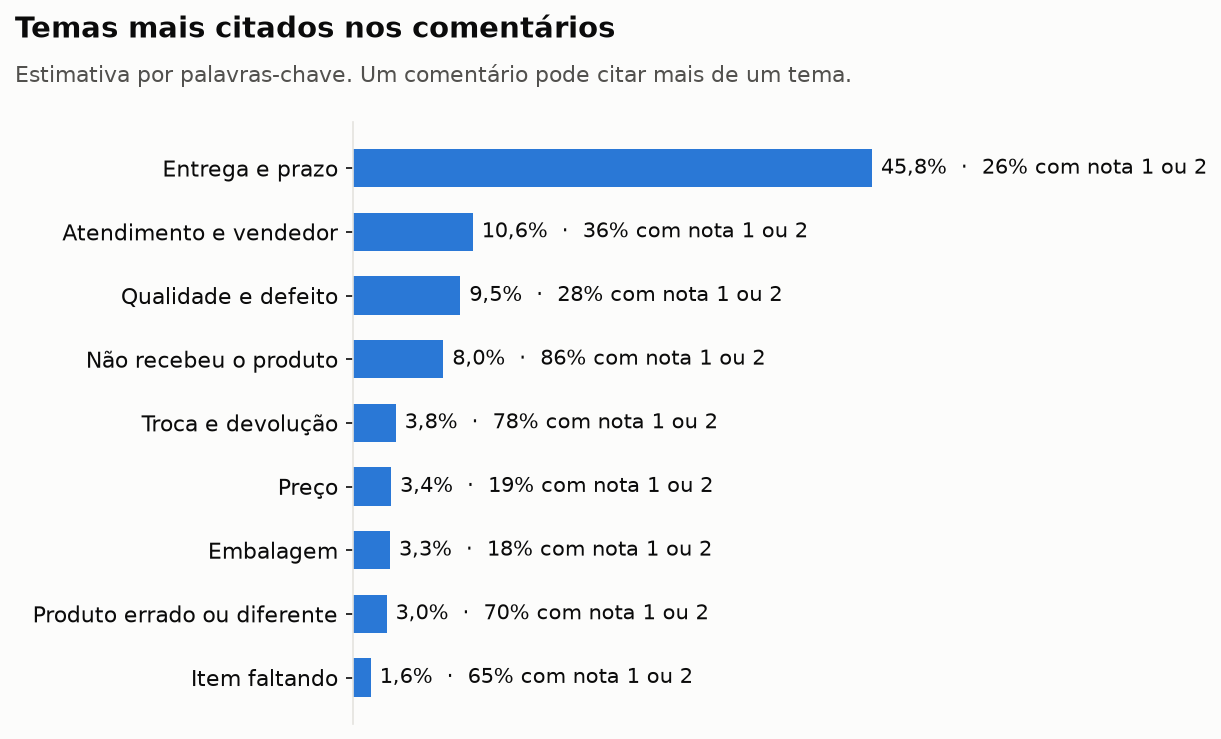

In [13]:
display(Image("../images/04_temas_por_palavra_chave.png"))

In [14]:
pd.DataFrame(resumo["temas_por_palavra_chave"]).T

,comentarios,pct_dos_comentarios,pct_com_nota_1_2
Entrega e prazo,18626.0,45.8,26.0
Atendimento e vendedor,4322.0,10.6,36.0
Qualidade e defeito,3856.0,9.5,28.0
Não recebeu o produto,3266.0,8.0,86.0
Troca e devolução,1531.0,3.8,78.0
Embalagem,1360.0,3.3,18.0
Produto errado ou diferente,1220.0,3.0,70.0
Preço,1372.0,3.4,19.0
Item faltando,653.0,1.6,65.0


Entrega é o tema mais citado, em 45,8% dos comentários. A maior parte desses
comentários é positiva, como "chegou antes do prazo", e 26% têm nota 1 ou 2.

Os temas com mais notas baixas são não recebimento do produto (86%), troca e
devolução (78%) e produto errado (70%).

Como entrega aparece tanto em elogios quanto em reclamações, a busca vai precisar
diferenciar os dois casos.

## 7. Resumo das decisões

| Resultado da análise | Decisão |
|---|---|
| 789 `review_id` repetidos em dois pedidos, com o mesmo texto | Manter uma avaliação por `review_id` |
| 56,9% das avaliações não têm título nem comentário | Usar apenas avaliações com algum texto |
| O título complementa o comentário | Juntar título e comentário em um único texto |
| 14,9% têm só elogio genérico | Não entram na base |
| Comentários com no máximo 200 caracteres | Uma avaliação por documento, sem dividir o texto |
| 3.806 comentários com quebra de linha | Trocar quebra de linha por espaço |
| 2 avaliações com celular e 2 com link | Mascarar como `[CELULAR]` e `[LINK]` |
| Notas baixas têm mais comentários | Frequências calculadas sobre os comentários |
| Textos com termos de instrução | No prompt, avaliações separadas das instruções |